In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\asus\OneDrive\Desktop\PayGaurd_AI\data\raw\paysim.csv")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df.shape

(1048575, 11)

In [3]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [4]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   step            1048575 non-null  int64  
 1   type            1048575 non-null  str    
 2   amount          1048575 non-null  float64
 3   nameOrig        1048575 non-null  str    
 4   oldbalanceOrg   1048575 non-null  float64
 5   newbalanceOrig  1048575 non-null  float64
 6   nameDest        1048575 non-null  str    
 7   oldbalanceDest  1048575 non-null  float64
 8   newbalanceDest  1048575 non-null  float64
 9   isFraud         1048575 non-null  int64  
 10  isFlaggedFraud  1048575 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 116.4 MB


In [6]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [7]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

step              0.0
type              0.0
amount            0.0
nameOrig          0.0
oldbalanceOrg     0.0
newbalanceOrig    0.0
nameDest          0.0
oldbalanceDest    0.0
newbalanceDest    0.0
isFraud           0.0
isFlaggedFraud    0.0
dtype: float64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["isFraud"].value_counts()

isFraud
0    1047433
1       1142
Name: count, dtype: int64

In [10]:
df["isFraud"].value_counts(normalize=True) * 100

isFraud
0    99.89109
1     0.10891
Name: proportion, dtype: float64

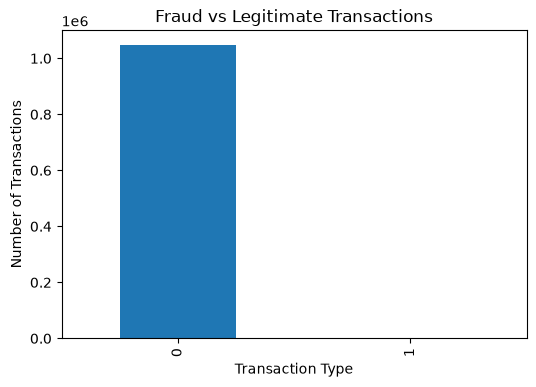

In [11]:
df["isFraud"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

In [12]:
df["type"].value_counts()

type
CASH_OUT    373641
PAYMENT     353873
CASH_IN     227130
TRANSFER     86753
DEBIT         7178
Name: count, dtype: int64

In [13]:
fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"]
)

fraud_by_type

isFraud,0,1
type,,
CASH_IN,227130,0
CASH_OUT,373063,578
DEBIT,7178,0
PAYMENT,353873,0
TRANSFER,86189,564


In [14]:
fraud_rate_by_type = (
    df.groupby("type")["isFraud"]
    .mean() * 100
)

fraud_rate_by_type

type
CASH_IN     0.000000
CASH_OUT    0.154694
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.650122
Name: isFraud, dtype: float64

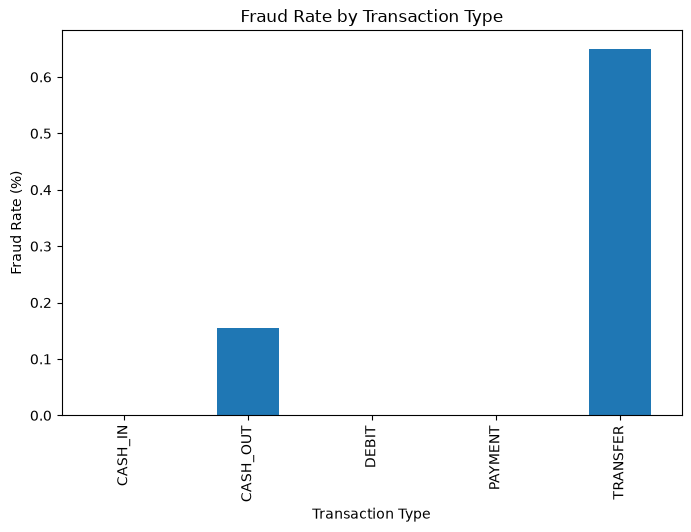

In [15]:
fraud_rate_by_type.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")

plt.show()

In [16]:
df["amount"].describe()

count    1.048575e+06
mean     1.586670e+05
std      2.649409e+05
min      1.000000e-01
25%      1.214907e+04
50%      7.634333e+04
75%      2.137619e+05
max      1.000000e+07
Name: amount, dtype: float64

In [17]:
df.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
isFraud,,,,,
0,1047433,1.575397e+05,76214.97,0.1,6419835.27
1,1142,1.192629e+06,353179.45,119.0,10000000.00


In [18]:
df.nlargest(10, "amount")[
    ["step", "type", "amount", "nameOrig", "nameDest", "isFraud"]
]

,step,type,amount,nameOrig,nameDest,isFraud
4440,4,TRANSFER,10000000.0,C7162498,C945327594,1
4441,4,CASH_OUT,10000000.0,C351297720,C766681183,1
481250,19,TRANSFER,10000000.0,C416779475,C380259496,1
481251,19,CASH_OUT,10000000.0,C2050703310,C1622860679,1
586311,33,TRANSFER,10000000.0,C1439740840,C875288652,1
586312,33,CASH_OUT,10000000.0,C29118015,C1379703840,1
1030559,72,TRANSFER,10000000.0,C53057884,C588547519,1
1030560,72,CASH_OUT,10000000.0,C1438388258,C1089455271,1
1030661,82,TRANSFER,10000000.0,C1237313447,C1468356154,1
1030662,82,CASH_OUT,10000000.0,C1079335762,C615227407,1


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   step            1048575 non-null  int64  
 1   type            1048575 non-null  str    
 2   amount          1048575 non-null  float64
 3   nameOrig        1048575 non-null  str    
 4   oldbalanceOrg   1048575 non-null  float64
 5   newbalanceOrig  1048575 non-null  float64
 6   nameDest        1048575 non-null  str    
 7   oldbalanceDest  1048575 non-null  float64
 8   newbalanceDest  1048575 non-null  float64
 9   isFraud         1048575 non-null  int64  
 10  isFlaggedFraud  1048575 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 116.4 MB


In [20]:
df["isFraud"].value_counts()

isFraud
0    1047433
1       1142
Name: count, dtype: int64

Calculate fraud rate by transaction type

In [21]:
fraud_rate = (
    df.groupby("type")["isFraud"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

fraud_rate

type
TRANSFER    0.650122
CASH_OUT    0.154694
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64

Make your first fraud visualization

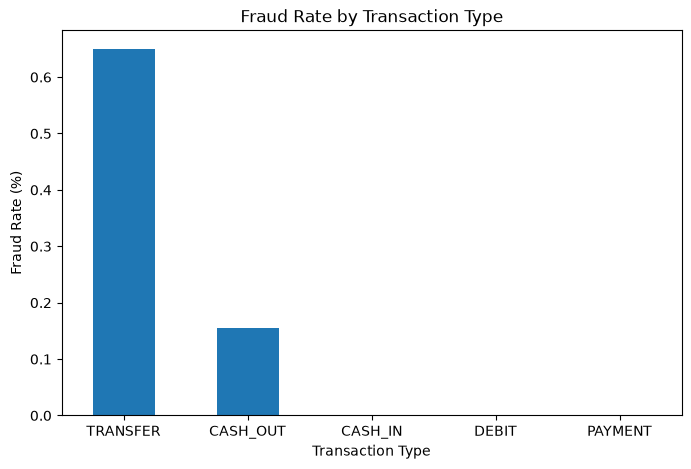

In [22]:
fraud_rate.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)

plt.show()

Analyze transaction amounts

In [23]:
df["amount"].describe()

count    1.048575e+06
mean     1.586670e+05
std      2.649409e+05
min      1.000000e-01
25%      1.214907e+04
50%      7.634333e+04
75%      2.137619e+05
max      1.000000e+07
Name: amount, dtype: float64

In [24]:
df.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
isFraud,,,,,
0,1047433,1.575397e+05,76214.97,0.1,6419835.27
1,1142,1.192629e+06,353179.45,119.0,10000000.00


Find the largest fraudulent transactions

In [25]:
df[df["isFraud"] == 1].nlargest(
    10,
    "amount"
)[
    [
        "step",
        "type",
        "amount",
        "nameOrig",
        "nameDest",
        "isFraud"
    ]
]

,step,type,amount,nameOrig,nameDest,isFraud
4440,4,TRANSFER,10000000.0,C7162498,C945327594,1
4441,4,CASH_OUT,10000000.0,C351297720,C766681183,1
481250,19,TRANSFER,10000000.0,C416779475,C380259496,1
481251,19,CASH_OUT,10000000.0,C2050703310,C1622860679,1
586311,33,TRANSFER,10000000.0,C1439740840,C875288652,1
586312,33,CASH_OUT,10000000.0,C29118015,C1379703840,1
1030559,72,TRANSFER,10000000.0,C53057884,C588547519,1
1030560,72,CASH_OUT,10000000.0,C1438388258,C1089455271,1
1030661,82,TRANSFER,10000000.0,C1237313447,C1468356154,1
1030662,82,CASH_OUT,10000000.0,C1079335762,C615227407,1


In [26]:

df["type"].value_counts()


type
CASH_OUT    373641
PAYMENT     353873
CASH_IN     227130
TRANSFER     86753
DEBIT         7178
Name: count, dtype: int64

In [27]:
fraud_rate

type
TRANSFER    0.650122
CASH_OUT    0.154694
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64

In [28]:
df.duplicated().sum()

np.int64(0)

Compare average transaction amount

In [29]:
df.groupby("isFraud")["amount"].mean()

isFraud
0    1.575397e+05
1    1.192629e+06
Name: amount, dtype: float64

In [30]:
df.groupby("isFraud")["amount"].median()

isFraud
0     76214.97
1    353179.45
Name: amount, dtype: float64

Visualize transaction amounts

In [31]:
sample_df = df.sample(
    n=20000,
    random_state=42
)

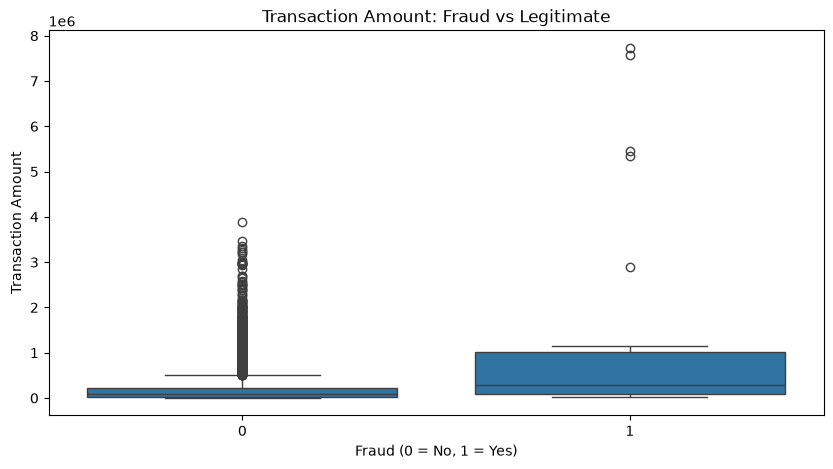

In [32]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=sample_df,
    x="isFraud",
    y="amount"
)

plt.title("Transaction Amount: Fraud vs Legitimate")
plt.xlabel("Fraud (0 = No, 1 = Yes)")
plt.ylabel("Transaction Amount")

plt.show()

Check fraudulent transactions by type

In [33]:
fraud_transactions = df[df["isFraud"] == 1]

fraud_transactions["type"].value_counts()

type
CASH_OUT    578
TRANSFER    564
Name: count, dtype: int64

In [34]:
df.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
isFraud,,,,,
0,1047433,1.575397e+05,76214.97,0.1,6419835.27
1,1142,1.192629e+06,353179.45,119.0,10000000.00


FEATURE ENGINEERING

In [35]:
df_model = df.copy()

In [36]:
df_model.shape

(1048575, 11)

In [37]:
df_model["hour"] = df_model["step"] % 24

In [38]:
df_model[["step", "hour"]].head(10)

,step,hour
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [39]:
df_model["is_night"] = (
    (df_model["hour"] >= 0) &
    (df_model["hour"] < 6)
).astype(int)

In [40]:
df_model[["hour", "is_night"]].head(20)

,hour,is_night
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [41]:
df_model["balance_change_orig"] = (
    df_model["oldbalanceOrg"] -
    df_model["newbalanceOrig"]
)

In [42]:
df_model["balance_change_dest"] = (
    df_model["newbalanceDest"] -
    df_model["oldbalanceDest"]
)

In [43]:
df_model["orig_balance_error"] = (
    df_model["oldbalanceOrg"]
    - df_model["newbalanceOrig"]
    - df_model["amount"]
)

In [44]:
df_model["is_large_amount"] = (
    df_model["amount"] > df_model["amount"].quantile(0.99)
).astype(int)

In [45]:
df_model["is_large_amount"].value_counts()

is_large_amount
0    1038089
1      10486
Name: count, dtype: int64

In [46]:
df_model["log_amount"] = np.log1p(
    df_model["amount"]
)

In [47]:
df_model[
    [
        "amount",
        "hour",
        "is_night",
        "balance_change_orig",
        "balance_change_dest",
        "orig_balance_error",
        "is_large_amount",
        "log_amount",
        "isFraud"
    ]
].head()

,amount,hour,is_night,balance_change_orig,balance_change_dest,orig_balance_error,is_large_amount,log_amount,isFraud
0,9839.64,1,1,9839.64,0.0,1.455192e-11,0,9.194276,0
1,1864.28,1,1,1864.28,0.0,-1.136868e-12,0,7.531166,0
2,181.00,1,1,181.00,0.0,0.000000e+00,0,5.204007,1
3,181.00,1,1,181.00,-21182.0,0.000000e+00,0,5.204007,1
4,11668.14,1,1,11668.14,0.0,0.000000e+00,0,9.364703,0


In [48]:
numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "hour",
    "is_night",
    "balance_change_orig",
    "balance_change_dest",
    "orig_balance_error",
    "is_large_amount",
    "log_amount",
    "isFraud"
]

df_model[numeric_features].corr()["isFraud"].sort_values(
    ascending=False
)

isFraud                1.000000
balance_change_orig    0.293785
amount                 0.128862
is_large_amount        0.077465
step                   0.045030
is_night               0.044196
balance_change_dest    0.032038
log_amount             0.031750
orig_balance_error     0.020029
oldbalanceOrg          0.003829
newbalanceDest        -0.000495
oldbalanceDest        -0.007553
newbalanceOrig        -0.009438
hour                  -0.021260
Name: isFraud, dtype: float64

In [49]:
df_model.to_csv(
    "../data/processed/paysim_features.csv",
    index=False
)

In [50]:
df_model.shape

(1048575, 18)

In [51]:
df_model[numeric_features].corr()["isFraud"].sort_values(
    ascending=False
)

isFraud                1.000000
balance_change_orig    0.293785
amount                 0.128862
is_large_amount        0.077465
step                   0.045030
is_night               0.044196
balance_change_dest    0.032038
log_amount             0.031750
orig_balance_error     0.020029
oldbalanceOrg          0.003829
newbalanceDest        -0.000495
oldbalanceDest        -0.007553
newbalanceOrig        -0.009438
hour                  -0.021260
Name: isFraud, dtype: float64

Fraud Detection ML

In [52]:
features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "hour",
    "is_night",
    "balance_change_orig",
    "balance_change_dest",
    "orig_balance_error",
    "is_large_amount",
    "log_amount",
    "type"
]

target = "isFraud"

In [53]:
X = df_model[features].copy()
y = df_model[target].copy()

In [54]:
X.shape

(1048575, 14)

In [55]:
y.shape

(1048575,)

Convert type into numbers

In [56]:
X = pd.get_dummies(
    X,
    columns=["type"],
    drop_first=True,
    dtype=int
)

In [57]:
X.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,hour,is_night,balance_change_orig,balance_change_dest,orig_balance_error,is_large_amount,log_amount,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,160296.36,0.0,0.0,1,1,9839.64,0.0,1.455192e-11,0,9.194276,0,0,1,0
1,1,1864.28,21249.0,19384.72,0.0,0.0,1,1,1864.28,0.0,-1.136868e-12,0,7.531166,0,0,1,0
2,1,181.00,181.0,0.00,0.0,0.0,1,1,181.00,0.0,0.000000e+00,0,5.204007,0,0,0,1
3,1,181.00,181.0,0.00,21182.0,0.0,1,1,181.00,-21182.0,0.000000e+00,0,5.204007,1,0,0,0
4,1,11668.14,41554.0,29885.86,0.0,0.0,1,1,11668.14,0.0,0.000000e+00,0,9.364703,0,0,1,0


In [58]:
X.shape

(1048575, 17)

In [59]:
X.columns.tolist()

['step',
 'amount',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest',
 'hour',
 'is_night',
 'balance_change_orig',
 'balance_change_dest',
 'orig_balance_error',
 'is_large_amount',
 'log_amount',
 'type_CASH_OUT',
 'type_DEBIT',
 'type_PAYMENT',
 'type_TRANSFER']

Train/Test Split 

In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [61]:
features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "hour",
    "is_night",
    "balance_change_orig",
    "balance_change_dest",
    "orig_balance_error",
    "is_large_amount",
    "log_amount",
    "type"
]

target = "isFraud"

print("Features and target defined successfully!")

Features and target defined successfully!


In [62]:
X = df_model[features].copy()
y = df_model[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1048575, 14)
y shape: (1048575,)


In [63]:
X = pd.get_dummies(
    X,
    columns=["type"],
    drop_first=True,
    dtype=int
)

print("Encoding completed!")
print("New X shape:", X.shape)

Encoding completed!
New X shape: (1048575, 17)


In [64]:
X.columns.tolist()

['step',
 'amount',
 'oldbalanceOrg',
 'newbalanceOrig',
 'oldbalanceDest',
 'newbalanceDest',
 'hour',
 'is_night',
 'balance_change_orig',
 'balance_change_dest',
 'orig_balance_error',
 'is_large_amount',
 'log_amount',
 'type_CASH_OUT',
 'type_DEBIT',
 'type_PAYMENT',
 'type_TRANSFER']

In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (838860, 17)
Testing data: (209715, 17)


In [66]:
print("Training fraud distribution:")
print(y_train.value_counts())

print("\nTesting fraud distribution:")
print(y_test.value_counts())

Training fraud distribution:
isFraud
0    837946
1       914
Name: count, dtype: int64

Testing fraud distribution:
isFraud
0    209487
1       228
Name: count, dtype: int64


In [67]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

Training data: (838860, 17)
Testing data: (209715, 17)
isFraud
0    837946
1       914
Name: count, dtype: int64
isFraud
0    209487
1       228
Name: count, dtype: int64


In [68]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Scaling completed!
Training shape: (838860, 17)
Testing shape: (209715, 17)


In [69]:
scaler.fit_transform(X_train)

array([[-1.14997997, -0.59078472, -0.28713063, ..., -0.08280781,
         1.4022136 , -0.30026272],
       [ 0.6422714 ,  0.77573402, -0.27735046, ..., -0.08280781,
        -0.71315811, -0.30026272],
       [-0.7659261 , -0.5829553 , -0.29416781, ..., -0.08280781,
         1.4022136 , -0.30026272],
       ...,
       [-0.70191712, -0.25539538, -0.27672938, ..., -0.08280781,
        -0.71315811, -0.30026272],
       [-0.89394406,  0.9289454 , -0.29416781, ..., -0.08280781,
        -0.71315811, -0.30026272],
       [-0.70191712,  0.41215734,  0.72265881, ..., -0.08280781,
        -0.71315811, -0.30026272]], shape=(838860, 17))

In [70]:
scaler.transform(X_test)

array([[-1.14997997, -0.56047196, -0.29416781, ..., -0.08280781,
         1.4022136 , -0.30026272],
       [ 0.77028936,  2.08941588, -0.28732445, ..., -0.08280781,
        -0.71315811,  3.33041674],
       [-0.44588121, -0.11226426, -0.28016802, ..., -0.08280781,
        -0.71315811, -0.30026272],
       ...,
       [-0.38187224,  0.10181058, -0.29416781, ..., -0.08280781,
        -0.71315811, -0.30026272],
       [ 0.83429834, -0.53374743, -0.25187486, ..., -0.08280781,
         1.4022136 , -0.30026272],
       [-0.50989019, -0.51882149, -0.27417449, ..., -0.08280781,
         1.4022136 , -0.30026272]], shape=(209715, 17))

In [71]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [72]:
y_pred = lr_model.predict(X_test_scaled)

print("Predictions completed!")

Predictions completed!


In [73]:
y_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

print(y_proba[:10])

[7.20471235e-27 9.65958681e-03 1.05568373e-01 1.24809548e-32
 6.27590870e-04 5.76140021e-18 1.82120175e-01 5.30077556e-27
 8.83964272e-02 6.17823903e-02]


In [74]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      0.96      0.98    209487
       Fraud       0.02      0.95      0.04       228

    accuracy                           0.96    209715
   macro avg       0.51      0.95      0.51    209715
weighted avg       1.00      0.96      0.98    209715



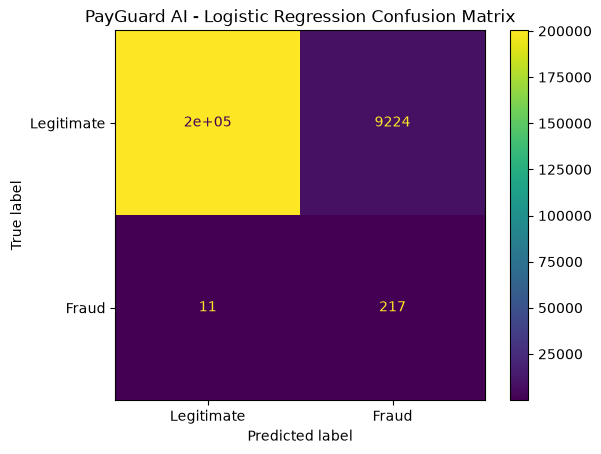

In [75]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot()

plt.title("PayGuard AI - Logistic Regression Confusion Matrix")
plt.show()

In [76]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9880338218031199
PR-AUC: 0.441498043806006


In [77]:
!pip install joblib

Defaulting to user installation because normal site-packages is not writeable


In [78]:
import joblib

joblib.dump(lr_model, "../models/logistic_regression.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [79]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      0.96      0.98    209487
       Fraud       0.02      0.95      0.04       228

    accuracy                           0.96    209715
   macro avg       0.51      0.95      0.51    209715
weighted avg       1.00      0.96      0.98    209715



In [80]:
print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9880338218031199
PR-AUC: 0.441498043806006


Analyze the Confusion Matrix

In [81]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[200263   9224]
 [    11    217]]


In [82]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 200263
False Positives: 9224
False Negatives: 11
True Positives : 217


In [83]:
y_proba

array([7.20471235e-27, 9.65958681e-03, 1.05568373e-01, ...,
       2.38199428e-02, 2.12652174e-27, 1.88639457e-27], shape=(209715,))

In [84]:
fraud_probabilities = pd.DataFrame({
    "actual": y_test.values,
    "probability": y_proba
})

fraud_probabilities[fraud_probabilities["actual"] == 1].describe()

,actual,probability
count,228.0,228.000000
mean,1.0,0.902741
std,0.0,0.188902
min,1.0,0.004049
25%,1.0,0.890240
50%,1.0,0.996114
75%,1.0,1.000000
max,1.0,1.000000


In [85]:
fraud_probabilities[fraud_probabilities["actual"] == 0].describe()

,actual,probability
count,209487.0,2.094870e+05
mean,0.0,7.493642e-02
std,0.0,1.680607e-01
min,0.0,7.310711e-281
25%,0.0,4.429998e-27
50%,0.0,2.196853e-20
75%,0.0,5.484740e-02
max,0.0,1.000000e+00


In [86]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

for threshold in thresholds:

    predictions = (y_proba >= threshold).astype(int)

    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.10 | Precision: 0.006 | Recall: 0.987 | F1: 0.011
Threshold: 0.20 | Precision: 0.008 | Recall: 0.978 | F1: 0.017
Threshold: 0.30 | Precision: 0.012 | Recall: 0.978 | F1: 0.024
Threshold: 0.40 | Precision: 0.017 | Recall: 0.965 | F1: 0.033
Threshold: 0.50 | Precision: 0.023 | Recall: 0.952 | F1: 0.045
Threshold: 0.60 | Precision: 0.032 | Recall: 0.925 | F1: 0.062
Threshold: 0.70 | Precision: 0.046 | Recall: 0.882 | F1: 0.087
Threshold: 0.80 | Precision: 0.068 | Recall: 0.829 | F1: 0.126
Threshold: 0.90 | Precision: 0.113 | Recall: 0.741 | F1: 0.197


In [87]:
import numpy as np

threshold_values = np.arange(0.05, 0.96, 0.05)

results = []

for threshold in threshold_values:

    predictions = (y_proba >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

threshold_df.sort_values(
    "f1",
    ascending=False
).head(10)

,threshold,precision,recall,f1
18,0.95,0.165584,0.671053,0.265625
17,0.90,0.113271,0.741228,0.196512
16,0.85,0.086001,0.789474,0.155106
15,0.80,0.068108,0.828947,0.125874
14,0.75,0.055336,0.859649,0.103979
13,0.70,0.045537,0.881579,0.086601
12,0.65,0.038419,0.907895,0.073718
11,0.60,0.032165,0.925439,0.062169
10,0.55,0.027030,0.938596,0.052548
9,0.50,0.022985,0.951754,0.044886


In [88]:
threshold_df.sort_values(
    "f1",
    ascending=False
).head(10)

,threshold,precision,recall,f1
18,0.95,0.165584,0.671053,0.265625
17,0.90,0.113271,0.741228,0.196512
16,0.85,0.086001,0.789474,0.155106
15,0.80,0.068108,0.828947,0.125874
14,0.75,0.055336,0.859649,0.103979
13,0.70,0.045537,0.881579,0.086601
12,0.65,0.038419,0.907895,0.073718
11,0.60,0.032165,0.925439,0.062169
10,0.55,0.027030,0.938596,0.052548
9,0.50,0.022985,0.951754,0.044886


In [89]:
X_train
X_test

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,hour,is_night,balance_change_orig,balance_change_dest,orig_balance_error,is_large_amount,log_amount,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
48643,9,10293.04,0.00,0.00,0.00,0.00,9,0,0.00,0.00,-1.029304e+04,0,9.239320,0,0,1,0
782030,39,712067.18,20373.00,0.00,43650.90,832688.04,15,0,20373.00,789037.14,-6.916942e+05,0,13.475929,0,0,0,1
511473,20,128992.62,41678.00,0.00,281837.79,410830.41,20,0,41678.00,128992.62,-8.731462e+04,0,11.767518,1,0,0,0
805802,40,1203.29,376.00,0.00,2154882.62,2156085.91,16,0,376.00,1203.29,-8.272900e+02,0,7.093645,0,1,0,0
34620,8,950758.05,1287.00,0.00,2066.00,411762.11,8,0,1287.00,409696.11,-9.494711e+05,0,13.765016,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
567402,23,15093.79,196501.68,181407.89,0.00,0.00,23,0,15093.79,0.00,-2.182787e-11,0,9.622105,0,0,1,0
525340,20,5288.60,8074.00,2785.40,0.00,0.00,20,0,5288.60,0.00,0.000000e+00,0,8.573498,0,0,1,0
542231,21,185686.41,0.00,0.00,271608.07,457294.48,21,0,0.00,185686.41,-1.856864e+05,0,12.131820,1,0,0,0
818344,40,17370.54,125908.00,108537.46,0.00,0.00,16,0,17370.54,0.00,-7.275958e-12,0,9.762589,0,0,1,0


In [90]:
X_train_scaled
X_test_scaled

array([[-1.14997997, -0.56047196, -0.29416781, ..., -0.08280781,
         1.4022136 , -0.30026272],
       [ 0.77028936,  2.08941588, -0.28732445, ..., -0.08280781,
        -0.71315811,  3.33041674],
       [-0.44588121, -0.11226426, -0.28016802, ..., -0.08280781,
        -0.71315811, -0.30026272],
       ...,
       [-0.38187224,  0.10181058, -0.29416781, ..., -0.08280781,
        -0.71315811, -0.30026272],
       [ 0.83429834, -0.53374743, -0.25187486, ..., -0.08280781,
         1.4022136 , -0.30026272],
       [-0.50989019, -0.51882149, -0.27417449, ..., -0.08280781,
         1.4022136 , -0.30026272]], shape=(209715, 17))

In [91]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [92]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [93]:
rf_pred = rf_model.predict(X_test)

rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

Predictions completed!


In [94]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    rf_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    209487
       Fraud       1.00      0.98      0.99       228

    accuracy                           1.00    209715
   macro avg       1.00      0.99      0.99    209715
weighted avg       1.00      1.00      1.00    209715



In [95]:
from sklearn.metrics import roc_auc_score, average_precision_score

rf_roc_auc = roc_auc_score(y_test, rf_proba)
rf_pr_auc = average_precision_score(y_test, rf_proba)

print("Random Forest ROC-AUC:", rf_roc_auc)
print("Random Forest PR-AUC:", rf_pr_auc)

Random Forest ROC-AUC: 0.9925424024553213
Random Forest PR-AUC: 0.9849274671879573


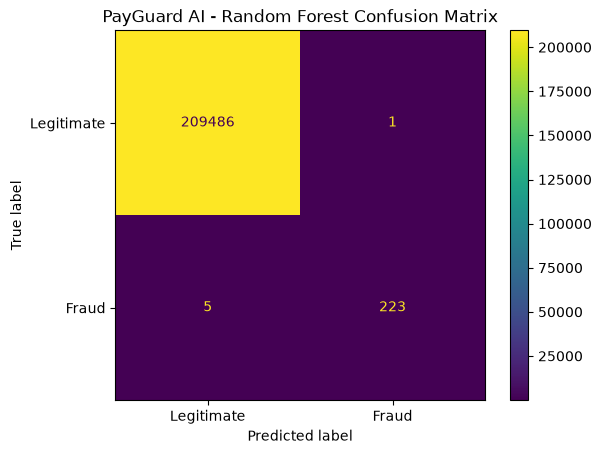

In [96]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

rf_cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot()

plt.title("PayGuard AI - Random Forest Confusion Matrix")
plt.show()

In [97]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc
    ],
    "PR-AUC": [
        pr_auc,
        rf_pr_auc
    ]
})

comparison

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.988034,0.441498
1,Random Forest,0.992542,0.984927


In [98]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance.head(15)

,feature,importance
10,orig_balance_error,0.295861
8,balance_change_orig,0.182658
3,newbalanceOrig,0.149095
0,step,0.073158
2,oldbalanceOrg,0.053955
15,type_PAYMENT,0.050321
16,type_TRANSFER,0.037444
12,log_amount,0.037435
1,amount,0.035079
9,balance_change_dest,0.023538


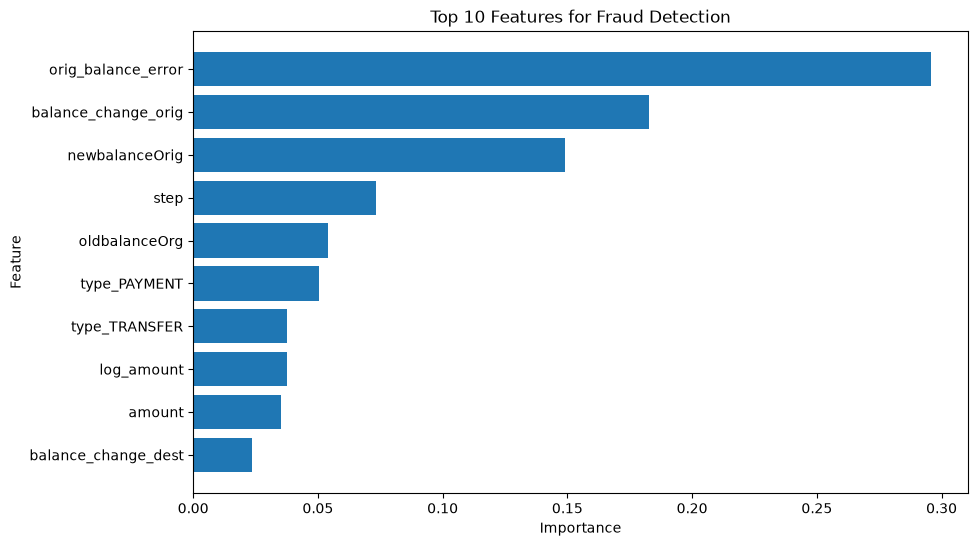

In [99]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.title("Top 10 Features for Fraud Detection")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [100]:
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    209487
       Fraud       1.00      0.98      0.99       228

    accuracy                           1.00    209715
   macro avg       1.00      0.99      0.99    209715
weighted avg       1.00      1.00      1.00    209715



In [101]:
print("Random Forest ROC-AUC:", rf_roc_auc)
print("Random Forest PR-AUC:", rf_pr_auc)

Random Forest ROC-AUC: 0.9925424024553213
Random Forest PR-AUC: 0.9849274671879573


In [102]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance.head(15)

,feature,importance
10,orig_balance_error,0.295861
8,balance_change_orig,0.182658
3,newbalanceOrig,0.149095
0,step,0.073158
2,oldbalanceOrg,0.053955
15,type_PAYMENT,0.050321
16,type_TRANSFER,0.037444
12,log_amount,0.037435
1,amount,0.035079
9,balance_change_dest,0.023538


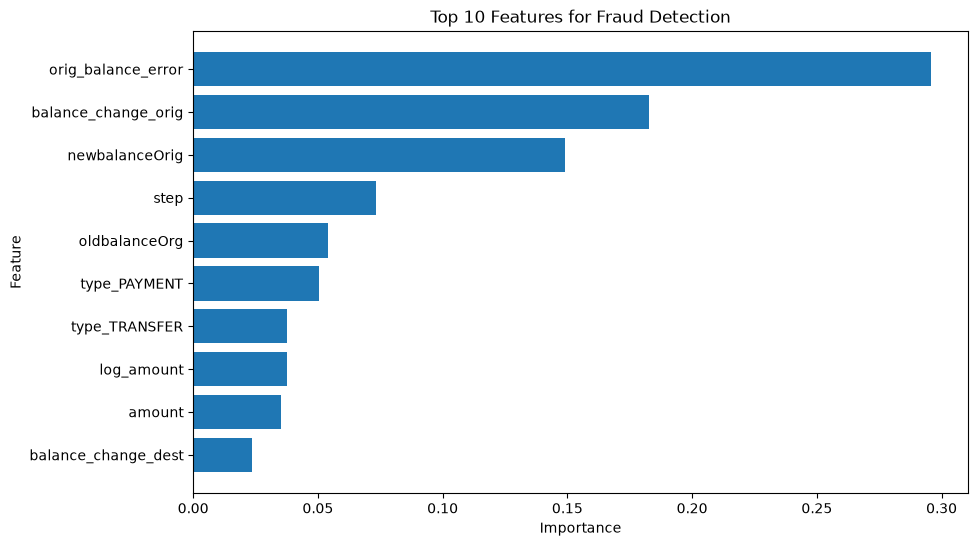

In [103]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.title("Top 10 Features for Fraud Detection")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [104]:
rf_cm = confusion_matrix(y_test, rf_pred)

tn, fp, fn, tp = rf_cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 209486
False Positives: 1
False Negatives: 5
True Positives : 223


In [105]:
rf_pred = rf_model.predict(X_test)

In [106]:
threshold_values = np.arange(0.10, 1.00, 0.05)

rf_threshold_results = []

for threshold in threshold_values:

    predictions = (rf_proba >= threshold).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    rf_threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

rf_threshold_df.sort_values(
    "f1",
    ascending=False
).head(10)

,threshold,precision,recall,f1
10,0.60,1.000000,0.978070,0.988914
9,0.55,1.000000,0.978070,0.988914
8,0.50,0.995536,0.978070,0.986726
12,0.70,1.000000,0.973684,0.986667
13,0.75,1.000000,0.973684,0.986667
11,0.65,1.000000,0.973684,0.986667
14,0.80,1.000000,0.969298,0.984410
7,0.45,0.986726,0.978070,0.982379
15,0.85,1.000000,0.947368,0.972973
6,0.40,0.944915,0.978070,0.961207


In [107]:
best_threshold_row = rf_threshold_df.loc[
    rf_threshold_df["f1"].idxmax()
]

best_threshold_row

threshold    0.550000
precision    1.000000
recall       0.978070
f1           0.988914
Name: 9, dtype: float64

In [108]:
import joblib

joblib.dump(
    rf_model,
    "../models/random_forest_fraud.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [109]:
joblib.dump(
    X_train.columns.tolist(),
    "../models/model_features.pkl"
)

print("Feature list saved successfully!")

Feature list saved successfully!


In [110]:
feature_importance.head(15)

,feature,importance
10,orig_balance_error,0.295861
8,balance_change_orig,0.182658
3,newbalanceOrig,0.149095
0,step,0.073158
2,oldbalanceOrg,0.053955
15,type_PAYMENT,0.050321
16,type_TRANSFER,0.037444
12,log_amount,0.037435
1,amount,0.035079
9,balance_change_dest,0.023538


In [111]:
tn, fp, fn, tp

(np.int64(209486), np.int64(1), np.int64(5), np.int64(223))

In [112]:
rf_threshold_df.sort_values(
    "f1",
    ascending=False
).head(10)

,threshold,precision,recall,f1
10,0.60,1.000000,0.978070,0.988914
9,0.55,1.000000,0.978070,0.988914
8,0.50,0.995536,0.978070,0.986726
12,0.70,1.000000,0.973684,0.986667
13,0.75,1.000000,0.973684,0.986667
11,0.65,1.000000,0.973684,0.986667
14,0.80,1.000000,0.969298,0.984410
7,0.45,0.986726,0.978070,0.982379
15,0.85,1.000000,0.947368,0.972973
6,0.40,0.944915,0.978070,0.961207


In [113]:
best_rf_threshold = 0.60

print("Final fraud threshold:", best_rf_threshold)

Final fraud threshold: 0.6


In [114]:
def predict_transaction(transaction_data):

    transaction = pd.DataFrame([transaction_data])

    # -----------------------------
    # Feature Engineering
    # -----------------------------

    transaction["hour"] = transaction["step"] % 24

    transaction["is_night"] = (
        (transaction["hour"] >= 0) &
        (transaction["hour"] < 6)
    ).astype(int)

    transaction["balance_change_orig"] = (
        transaction["oldbalanceOrg"]
        - transaction["newbalanceOrig"]
    )

    transaction["balance_change_dest"] = (
        transaction["newbalanceDest"]
        - transaction["oldbalanceDest"]
    )

    transaction["orig_balance_error"] = (
        transaction["oldbalanceOrg"]
        - transaction["newbalanceOrig"]
        - transaction["amount"]
    )

    transaction["is_large_amount"] = (
        transaction["amount"] >
        df_model["amount"].quantile(0.99)
    ).astype(int)

    transaction["log_amount"] = np.log1p(
        transaction["amount"]
    )

    # -----------------------------
    # Encode transaction type
    # -----------------------------

    transaction = pd.get_dummies(
        transaction,
        columns=["type"],
        drop_first=True,
        dtype=int
    )

    # -----------------------------
    # Match training columns
    # -----------------------------

    transaction = transaction.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # -----------------------------
    # Fraud probability
    # -----------------------------

    probability = rf_model.predict_proba(
        transaction
    )[0][1]

    # -----------------------------
    # Risk score
    # -----------------------------

    risk_score = round(probability * 100, 2)

    # -----------------------------
    # Risk category
    # -----------------------------

    if risk_score <= 30:
        risk_level = "LOW"

    elif risk_score <= 70:
        risk_level = "MEDIUM"

    else:
        risk_level = "HIGH"

    # -----------------------------
    # Fraud prediction
    # -----------------------------

    prediction = int(
        probability >= best_rf_threshold
    )

    if prediction == 1:
        result = "FRAUD"
    else:
        result = "LEGITIMATE"

    return {
        "prediction": result,
        "fraud_probability": round(probability, 4),
        "risk_score": risk_score,
        "risk_level": risk_level
    }

In [115]:
test_transaction = {
    "step": 100,
    "type": "TRANSFER",
    "amount": 500000,
    "oldbalanceOrg": 500000,
    "newbalanceOrig": 0,
    "oldbalanceDest": 100000,
    "newbalanceDest": 600000
}

In [116]:
print("================================")
print("        PAYGUARD AI")
print("================================")

print("Prediction       :", result["prediction"])
print("Fraud Probability:", result["fraud_probability"])
print("Risk Score       :", result["risk_score"], "/ 100")
print("Risk Level       :", result["risk_level"])

print("================================")

        PAYGUARD AI


NameError: name 'result' is not defined

In [ ]:
normal_transaction = {
    "step": 50,
    "type": "PAYMENT",
    "amount": 500,
    "oldbalanceOrg": 10000,
    "newbalanceOrig": 9500,
    "oldbalanceDest": 5000,
    "newbalanceDest": 5500
}

normal_result = predict_transaction(normal_transaction)

print(normal_result)

In [ ]:
best_rf_threshold = 0.60

In [ ]:
result = predict_transaction(test_transaction)
print(result)

In [ ]:
normal_result = predict_transaction(normal_transaction)
print(normal_result)

In [ ]:
!pip install shap

In [ ]:
import shap

print("SHAP imported successfully!")

In [ ]:
import joblib

rf_model = joblib.load("../models/random_forest_fraud.pkl")

print("Random Forest loaded successfully!")

In [ ]:
print(rf_model)

In [117]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [118]:
explainer = shap.TreeExplainer(rf_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [119]:
X_explain = X_test.iloc[:100]

print("Transactions selected:", X_explain.shape)

Transactions selected: (100, 17)


In [120]:
print(df_model.shape)

(1048575, 18)


In [121]:
shap_values = explainer.shap_values(X_explain)

print("SHAP values calculated!")

SHAP values calculated!


In [122]:
type(shap_values)

numpy.ndarray

In [123]:
np.array(shap_values).shape

(100, 17, 2)

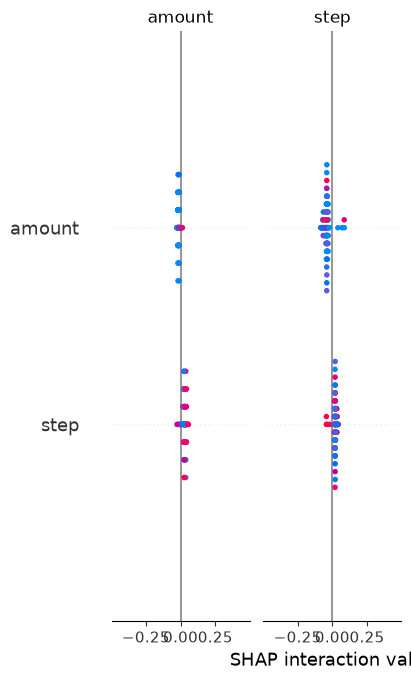

In [124]:
shap.summary_plot(
    shap_values,
    X_explain
)

In [125]:
transaction_index = 0

single_transaction = X_test.iloc[[transaction_index]]

print(single_transaction)

       step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
48643     9  10293.04            0.0             0.0             0.0   

       newbalanceDest  hour  is_night  balance_change_orig  \
48643             0.0     9         0                  0.0   

       balance_change_dest  orig_balance_error  is_large_amount  log_amount  \
48643                  0.0           -10293.04                0     9.23932   

       type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER  
48643              0           0             1              0  


In [126]:
actual_value = y_test.iloc[transaction_index]

prediction = rf_model.predict(single_transaction)[0]

probability = rf_model.predict_proba(
    single_transaction
)[0][1]

print("Actual:", actual_value)
print("Prediction:", prediction)
print("Fraud Probability:", probability)

Actual: 0
Prediction: 0
Fraud Probability: 0.0


In [127]:
single_shap = explainer.shap_values(single_transaction)

print(np.array(single_shap).shape)

(1, 17, 2)


In [128]:
explainer = shap.TreeExplainer(rf_model)

In [129]:
X_explain = X_test.iloc[:100]

In [130]:
shap_values = explainer.shap_values(X_explain)

print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(100, 17, 2)


In [131]:
single_transaction = X_test.iloc[[0]]

single_shap = explainer.shap_values(
    single_transaction
)

print(np.array(single_shap).shape)

(1, 17, 2)


In [132]:
shap_fraud = shap_values[:, :, 1]

print("Fraud SHAP shape:", shap_fraud.shape)

Fraud SHAP shape: (100, 17)


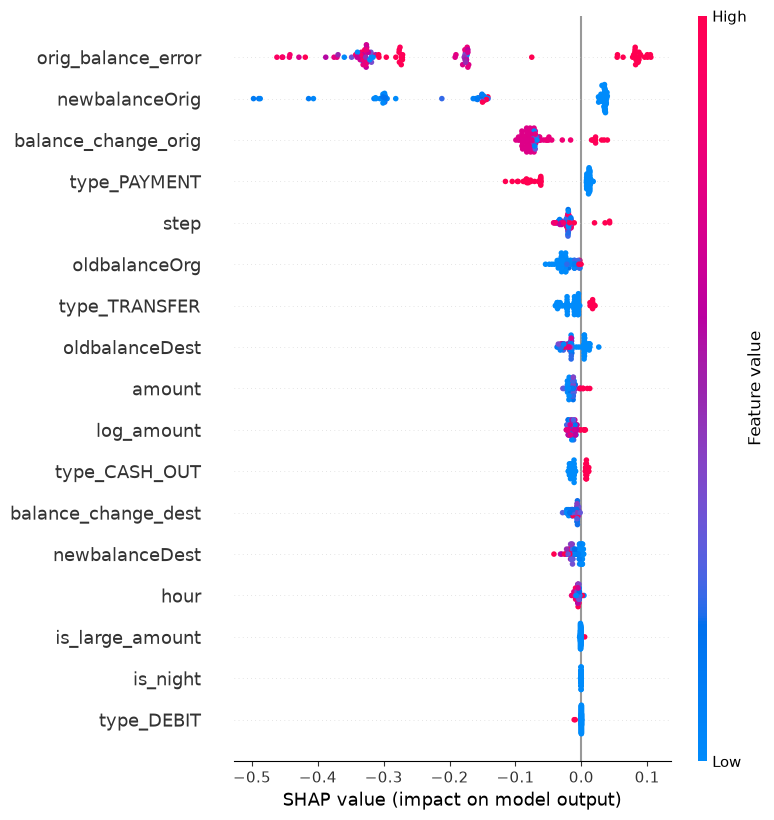

In [133]:
shap.summary_plot(
    shap_fraud,
    X_explain
)

In [134]:
shap_importance = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": np.abs(shap_fraud).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
)

shap_importance.head(15)

,feature,mean_abs_shap
10,orig_balance_error,0.245418
3,newbalanceOrig,0.126426
8,balance_change_orig,0.069574
15,type_PAYMENT,0.032328
0,step,0.022608
2,oldbalanceOrg,0.021636
16,type_TRANSFER,0.016194
4,oldbalanceDest,0.015945
1,amount,0.014272
12,log_amount,0.013980


In [135]:
single_shap_fraud = single_shap[0, :, 1]

print("Number of feature explanations:", len(single_shap_fraud))

Number of feature explanations: 17


In [136]:
single_explanation = pd.DataFrame({
    "feature": single_transaction.columns,
    "shap_value": single_shap_fraud,
    "feature_value": single_transaction.iloc[0].values
})

single_explanation["impact"] = np.where(
    single_explanation["shap_value"] > 0,
    "Increases fraud risk",
    "Decreases fraud risk"
)

single_explanation = single_explanation.sort_values(
    "shap_value",
    key=lambda x: abs(x),
    ascending=False
)

single_explanation

,feature,shap_value,feature_value,impact
10,orig_balance_error,-0.276216,-10293.04000,Decreases fraud risk
8,balance_change_orig,-0.077665,0.00000,Decreases fraud risk
15,type_PAYMENT,-0.061871,1.00000,Decreases fraud risk
3,newbalanceOrig,0.037178,0.00000,Increases fraud risk
2,oldbalanceOrg,-0.023723,0.00000,Decreases fraud risk
16,type_TRANSFER,-0.021428,0.00000,Decreases fraud risk
12,log_amount,-0.019854,9.23932,Decreases fraud risk
1,amount,-0.017244,10293.04000,Decreases fraud risk
13,type_CASH_OUT,-0.016250,0.00000,Decreases fraud risk
0,step,-0.015423,9.00000,Decreases fraud risk


In [137]:
top_reasons = single_explanation.head(5)

print("TOP FRAUD RISK FACTORS")
print("----------------------")

for _, row in top_reasons.iterrows():

    direction = row["impact"]

    print(
        f"{row['feature']}: "
        f"{direction} "
        f"(SHAP = {row['shap_value']:.4f})"
    )

TOP FRAUD RISK FACTORS
----------------------
orig_balance_error: Decreases fraud risk (SHAP = -0.2762)
balance_change_orig: Decreases fraud risk (SHAP = -0.0777)
type_PAYMENT: Decreases fraud risk (SHAP = -0.0619)
newbalanceOrig: Increases fraud risk (SHAP = 0.0372)
oldbalanceOrg: Decreases fraud risk (SHAP = -0.0237)


In [138]:
def explain_transaction(transaction_data):

    # Get prediction
    result = predict_transaction(transaction_data)

    # Recreate transaction features
    transaction = pd.DataFrame([transaction_data])

    transaction["hour"] = transaction["step"] % 24

    transaction["is_night"] = (
        (transaction["hour"] >= 0) &
        (transaction["hour"] < 6)
    ).astype(int)

    transaction["balance_change_orig"] = (
        transaction["oldbalanceOrg"]
        - transaction["newbalanceOrig"]
    )

    transaction["balance_change_dest"] = (
        transaction["newbalanceDest"]
        - transaction["oldbalanceDest"]
    )

    transaction["orig_balance_error"] = (
        transaction["oldbalanceOrg"]
        - transaction["newbalanceOrig"]
        - transaction["amount"]
    )

    transaction["is_large_amount"] = (
        transaction["amount"] >
        df_model["amount"].quantile(0.99)
    ).astype(int)

    transaction["log_amount"] = np.log1p(
        transaction["amount"]
    )

    transaction = pd.get_dummies(
        transaction,
        columns=["type"],
        drop_first=True,
        dtype=int
    )

    transaction = transaction.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # SHAP
    shap_result = explainer.shap_values(transaction)

    shap_fraud = shap_result[0, :, 1]

    explanation = pd.DataFrame({
        "feature": transaction.columns,
        "shap_value": shap_fraud
    })

    explanation = explanation.sort_values(
        "shap_value",
        key=lambda x: abs(x),
        ascending=False
    )

    # Top positive fraud factors
    positive_factors = explanation[
        explanation["shap_value"] > 0
    ].head(5)

    result["risk_factors"] = positive_factors[
        "feature"
    ].tolist()

    return result

In [139]:
payguard_result = explain_transaction(
    test_transaction
)

print(payguard_result)

{'prediction': 'FRAUD', 'fraud_probability': np.float64(0.8996), 'risk_score': np.float64(89.96), 'risk_level': 'HIGH', 'risk_factors': ['orig_balance_error', 'balance_change_orig', 'newbalanceOrig', 'step', 'hour']}


In [140]:
print("====================================")
print("          PAYGUARD AI")
print("====================================")

print("Prediction        :", payguard_result["prediction"])
print("Fraud Probability :", payguard_result["fraud_probability"])
print("Risk Score        :", payguard_result["risk_score"], "/ 100")
print("Risk Level        :", payguard_result["risk_level"])

print("\nTop Risk Factors:")

for factor in payguard_result["risk_factors"]:
    print("•", factor)

print("====================================")

          PAYGUARD AI
Prediction        : FRAUD
Fraud Probability : 0.8996
Risk Score        : 89.96 / 100
Risk Level        : HIGH

Top Risk Factors:
• orig_balance_error
• balance_change_orig
• newbalanceOrig
• step
• hour


In [141]:
test_transactions = [
    {
        "step": 50,
        "type": "PAYMENT",
        "amount": 500,
        "oldbalanceOrg": 10000,
        "newbalanceOrig": 9500,
        "oldbalanceDest": 5000,
        "newbalanceDest": 5500
    },

    {
        "step": 100,
        "type": "TRANSFER",
        "amount": 500000,
        "oldbalanceOrg": 500000,
        "newbalanceOrig": 0,
        "oldbalanceDest": 100000,
        "newbalanceDest": 600000
    },

    {
        "step": 200,
        "type": "CASH_OUT",
        "amount": 250000,
        "oldbalanceOrg": 300000,
        "newbalanceOrig": 50000,
        "oldbalanceDest": 0,
        "newbalanceDest": 250000
    },

    {
        "step": 300,
        "type": "TRANSFER",
        "amount": 1000000,
        "oldbalanceOrg": 1000000,
        "newbalanceOrig": 0,
        "oldbalanceDest": 50000,
        "newbalanceDest": 1050000
    },

    {
        "step": 400,
        "type": "PAYMENT",
        "amount": 1000,
        "oldbalanceOrg": 20000,
        "newbalanceOrig": 19000,
        "oldbalanceDest": 5000,
        "newbalanceDest": 6000
    }
]

print("Test transactions created:", len(test_transactions))

Test transactions created: 5


In [142]:
results = []

for transaction in test_transactions:

    result = explain_transaction(transaction)

    results.append({
        "type": transaction["type"],
        "amount": transaction["amount"],
        "prediction": result["prediction"],
        "fraud_probability": result["fraud_probability"],
        "risk_score": result["risk_score"],
        "risk_level": result["risk_level"]
    })

results_df = pd.DataFrame(results)

results_df

,type,amount,prediction,fraud_probability,risk_score,risk_level
0,PAYMENT,500,LEGITIMATE,0.0199,1.99,LOW
1,TRANSFER,500000,FRAUD,0.8996,89.96,HIGH
2,CASH_OUT,250000,LEGITIMATE,0.0796,7.96,LOW
3,TRANSFER,1000000,FRAUD,0.8797,87.97,HIGH
4,PAYMENT,1000,LEGITIMATE,0.0353,3.53,LOW


In [143]:
results_df["risk_level"].value_counts()

risk_level
LOW     3
HIGH    2
Name: count, dtype: int64

In [144]:
print("========================================")
print("          PAYGUARD AI SUMMARY")
print("========================================")

print("Total Transactions:", len(results_df))

print(
    "Fraud Predictions:",
    (results_df["prediction"] == "FRAUD").sum()
)

print(
    "Legitimate Predictions:",
    (results_df["prediction"] == "LEGITIMATE").sum()
)

print("\nRisk Distribution:")
print(results_df["risk_level"].value_counts())

print("========================================")

          PAYGUARD AI SUMMARY
Total Transactions: 5
Fraud Predictions: 2
Legitimate Predictions: 3

Risk Distribution:
risk_level
LOW     3
HIGH    2
Name: count, dtype: int64


In [145]:
def payguard_predict(transaction_data):

    result = explain_transaction(transaction_data)

    return {
        "prediction": result["prediction"],
        "risk_score": result["risk_score"],
        "risk_level": result["risk_level"],
        "fraud_probability": result["fraud_probability"],
        "risk_factors": result["risk_factors"]
    }

In [146]:
result = payguard_predict(test_transactions[1])

print(result)

{'prediction': 'FRAUD', 'risk_score': np.float64(89.96), 'risk_level': 'HIGH', 'fraud_probability': np.float64(0.8996), 'risk_factors': ['orig_balance_error', 'balance_change_orig', 'newbalanceOrig', 'step', 'hour']}


In [147]:
def display_payguard_result(result):

    print("\n====================================")
    print("           PAYGUARD AI")
    print("====================================")

    print(f"Prediction        : {result['prediction']}")
    print(f"Fraud Probability : {result['fraud_probability']:.2%}")
    print(f"Risk Score        : {result['risk_score']}/100")
    print(f"Risk Level        : {result['risk_level']}")

    print("\nRisk Factors:")

    if result["risk_factors"]:
        for factor in result["risk_factors"]:
            print(f"  • {factor}")
    else:
        print("  • No major risk factors identified")

    print("====================================")

In [148]:
result = payguard_predict(test_transactions[1])

display_payguard_result(result)


           PAYGUARD AI
Prediction        : FRAUD
Fraud Probability : 89.96%
Risk Score        : 89.96/100
Risk Level        : HIGH

Risk Factors:
  • orig_balance_error
  • balance_change_orig
  • newbalanceOrig
  • step
  • hour


In [149]:
results_df

,type,amount,prediction,fraud_probability,risk_score,risk_level
0,PAYMENT,500,LEGITIMATE,0.0199,1.99,LOW
1,TRANSFER,500000,FRAUD,0.8996,89.96,HIGH
2,CASH_OUT,250000,LEGITIMATE,0.0796,7.96,LOW
3,TRANSFER,1000000,FRAUD,0.8797,87.97,HIGH
4,PAYMENT,1000,LEGITIMATE,0.0353,3.53,LOW


In [150]:
results_df["risk_level"].value_counts()

risk_level
LOW     3
HIGH    2
Name: count, dtype: int64

In [151]:
result = payguard_predict(test_transactions[1])
display_payguard_result(result)


           PAYGUARD AI
Prediction        : FRAUD
Fraud Probability : 89.96%
Risk Score        : 89.96/100
Risk Level        : HIGH

Risk Factors:
  • orig_balance_error
  • balance_change_orig
  • newbalanceOrig
  • step
  • hour


In [152]:
print(type(rf_model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [153]:
import joblib

joblib.dump(rf_model, "../models/fraud_detection_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [154]:
import joblib

model = joblib.load("../models/fraud_detection_model.pkl")
features = joblib.load("../models/model_features.pkl")

print("Model type:", type(model))
print("Features:")
print(features)

Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Features:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour', 'is_night', 'balance_change_orig', 'balance_change_dest', 'orig_balance_error', 'is_large_amount', 'log_amount', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [155]:
import joblib
import os

model = joblib.load("../models/fraud_detection_model.pkl")
features = joblib.load("../models/model_features.pkl")
scaler = joblib.load("../models/scaler.pkl")

print("MODEL LOADED:", type(model).__name__)
print("NUMBER OF FEATURES:", len(features))
print("FEATURES:", features)
print("SCALER LOADED:", type(scaler).__name__)

MODEL LOADED: RandomForestClassifier
NUMBER OF FEATURES: 17
FEATURES: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour', 'is_night', 'balance_change_orig', 'balance_change_dest', 'orig_balance_error', 'is_large_amount', 'log_amount', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
SCALER LOADED: StandardScaler


In [156]:
import pandas as pd

df = pd.read_csv("../data/raw/paysim.csv")

fraud_transactions = df[df["isFraud"] == 1]

print("Total fraud transactions:", len(fraud_transactions))

fraud_transactions[
    [
        "step",
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest",
        "isFraud"
    ]
].head(10)

Total fraud transactions: 1142


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
2,1,TRANSFER,181.00,181.00,0.0,0.0,0.00,1
3,1,CASH_OUT,181.00,181.00,0.0,21182.0,0.00,1
251,1,TRANSFER,2806.00,2806.00,0.0,0.0,0.00,1
252,1,CASH_OUT,2806.00,2806.00,0.0,26202.0,0.00,1
680,1,TRANSFER,20128.00,20128.00,0.0,0.0,0.00,1
681,1,CASH_OUT,20128.00,20128.00,0.0,6268.0,12145.85,1
724,1,CASH_OUT,416001.33,0.00,0.0,102.0,9291619.62,1
969,1,TRANSFER,1277212.77,1277212.77,0.0,0.0,0.00,1
970,1,CASH_OUT,1277212.77,1277212.77,0.0,0.0,2444985.19,1
1115,1,TRANSFER,35063.63,35063.63,0.0,0.0,0.00,1
